# Partition uncertainties in projections of impacts, accounting for regression uncertainty

For the balanced panel of BCD-ME runs, MC draws over the VCV matrix of regression results

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import zarr
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar
from matplotlib import colors as mcolors

from funcs_support import get_filepaths,get_params,utility_save,load_shp
from funcs_readregs import coeffs_mortality, coeffs_gdppc, coeffs_payroll
from funcs_processing import calc_uncerts
from funcs_plot import plot_map, vals_to_color_triangle, create_segcmap

dir_list = get_params()

In [2]:
from distributed import Client

# Start dask client 
client = Client()
display(client)

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/8787/status,Workers: 6
Total threads: 18,Total memory: 72.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:41507,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:43097,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/36041/status,Memory: 12.00 GiB
Nanny: tcp://127.0.0.1:36077,


2026-06-05 11:22:18,247 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 0baa97559ec490370c183bfe0f84b29a initialized by task ('rechunk-merge-rechunk-transfer-2cc72ed2f9ea925a6edc1eaabb529eba', 0, 0, 9, 0, 7, 0, 0, 9, 2, 7) executed on worker tcp://127.0.0.1:37325
2026-06-05 11:22:18,286 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 6ee8b001eae00a32a837345ef05f9fdb initialized by task ('rechunk-merge-rechunk-transfer-2cc72ed2f9ea925a6edc1eaabb529eba', 0, 0, 9, 0, 0, 0, 0, 9, 2, 0) executed on worker tcp://127.0.0.1:44843
2026-06-05 11:22:20,463 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle ab4084c3a1b616934aa3e5d1936a789d initialized by task ('rechunk-merge-sub-rechunk-transfer-2cc72ed2f9ea925a6edc1eaabb529eba', 0, 0, 9, 0, 6, 0, 0, 9, 3, 6) executed on worker tcp://127.0.0.1:34591
2026-06-05 11:22:20,645 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 46e8df9dc5ed4aa7c1a2d01ccff2e4dc initialized by task ('rechunk-merge-sub-rechunk-tra

In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':True},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}


idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}


nsamples = 1000
rng = np.random.default_rng()

max_gwl = 3
nruns = {'mortality':13,
         'gdppc':13,
         'payroll':10}

## Calculate uncertainty with MC draws of regression uncertainty

In [9]:
overwrite = True
keep_idvs_ref_gwl = 2

def project_impact(ds,pred_var = 'tassumpoly',coeff_var = 'coeffs'):
    ''' Helper function for xr.map_blocks
    '''
    return (ds[coeff_var]*ds[pred_var]).sum('pred',skipna=False)
    
for proc in ['mortality','gdppc']:#params_proc:
    # Get filename of output uncertainty
    output_fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}_wregunc.zarr'

    if (not overwrite) and os.path.exists(output_fn):
        print(output_fn+' exists, skipped!')
        continue
    
    # Get filenames of aggregated climate predictors
    fns = np.sort(glob.glob(f'{dir_list['proc']}aggs/{params_proc[proc]['varname']}_*_{params_proc[proc]['geo_typ']}*{'popwght'*params_proc[proc]['popwght']}.zarr'))
    if params_proc[proc]['popwght']:
        fns = [fn for fn in fns if re.search(r'\_popwght\.zarr',fn)]
    else:
        fns = [fn for fn in fns if not re.search(r'\_popwght\.zarr',fn)]
    fns = {re.split(r'\_',re.split(r'\/',fn)[-1])[2]:fn for fn in fns}
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(obstreat='joint',joint_=True)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(obstreat='joint',joint_=True)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(obstreat='joint',joint_=True)
    else:
        raise KeyError()

    # Get MC samples of coefficients
    coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
               coeffs.coeffs.stack(v = ['pred','proj_base']),
               vcv.vcv.stack(v1 = ['pred_1','proj_base_1'],
                          v2 = ['pred_2','proj_base_2']).reset_index(['v1','v2']),
               input_core_dims = [['v'],['v1','v2']],
               output_core_dims = [['sidx','v']],
               kwargs = {'size':nsamples},
                                       dask = 'parallelized',
                                       dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                               vectorize=True)
    coeffs_mvn = coeffs_mvn.unstack('v')

    dss = []
    for mod in tqdm(fns):
        tmp_fn = f'{dir_list['proc']}tmp/d{proc}_regMCs_{mod}TMP.zarr'
        if overwrite or (not os.path.exists(tmp_fn+'/.done')):
    
            # Load aggregated climate predictor
            ds = xr.open_zarr(fns[mod],consolidated=False,decode_timedelta=False)
            if keep_idvs_ref_gwl not in ds.gwl.values:
                print(f'{mod} does not have the GWLs for desired panel scope, skipping.')
                continue
                
            if 'model' not in ds:
                ds = ds.assign_coords({'model':(('idv'),[mod]*ds.sizes['idv'])})
        
            # Isolate predictor variables
            if params_proc[proc]['varname'] == 'tassumpoly':
                ds['degree'] = [f'tassumpoly_{k}' for k in ds.degree.values]
                ds = ds.rename({'degree':'pred'})
            elif params_proc[proc]['varname'] == 'tasmaxbinF':
                ds['binF'] = [f'tasmaxbinF_{k}' for k in ds.binF.values]
                ds = ds.rename({'binF':'pred'})
            elif params_proc[proc]['varname'] == 'days90plus':
                ds = ds.rename({'binF':'pred'})
            else:
                raise KeyError()

            # Limit to just the balanced panel
            ds = ds.dropna('idv',how='all')
            ds = ds.sel(idv=ds.sel(gwl=keep_idvs_ref_gwl).dropna('idv',how='all').idv.values)
            # (also remove all-0 idvs in addition to all-nan idvs)
            ds = ds.sel(idv=ds.where(~(ds.sel(gwl=keep_idvs_ref_gwl,drop=True)[params_proc[proc]['varname']]==0).all('poly_idx').compute(),drop=True).idv)

            if ds.sizes['idv'] < nruns[proc]:
                print(f'{mod} does not have enough runs for desired panel size, skipping.')
                continue
            else:
                ds = ds.isel(idv=slice(0, nruns[proc]))

            # Make sure locid stays
            ds = ds.set_coords('locid')

            ds = ds.chunk({'pred':-1,'gwl':1,'proj_base':-1,'poly_idx':1000})

    
            # Calculate impact from linear regression model
            ds_tmp = xr.merge([ds[params_proc[proc]['varname']],
                              coeffs_mvn.chunk()],
                  join='inner',compat='no_conflicts').unify_chunks().reset_index('idv')
            ds[proc] = xr.map_blocks(project_impact,
                                      ds_tmp,
                                      [params_proc[proc]['varname']])
            # Calculate change in impact vs. GWL0.61
            ds['d'+proc] = ds[proc] - ds[proc].sel(gwl=0.61)
    
            # Add max gwl to coordinates, for referece
            ds = ds.assign_coords({'maxgwl':(('idv'),ds.gwl.isel(gwl=np.array([g if g != 0 else -1 
                                                              for g in (np.isnan(ds[params_proc[proc]['varname']]).
                                                                        argmax('gwl').
                                                                        max([d for d in ds[params_proc[proc]['varname']].sizes if d not in ['gwl','idv']])).
                                                                        load()])).values)})
    
            # Limit to just impact variable
            ds = ds[['d'+proc]]
            
    
            # Rechunk for uncertainty partitioning
            ds = ds.chunk({'poly_idx':100,'idv':-1,'sidx':-1,'proj_base':-1,'gwl':1})
    
            # Save temporary file
            ds['exprun'] = ds['experiment']+ds['run']
            ds = ds.set_index(idv = ['model','exprun'])
            ds = ds.reset_index('idv')
            ds.attrs = {'SOURCE':'4b_partition_uncertainty_wregunc.ipynb',
                         'DESCRIPTION':f'{proc} projections, calculated using {nsamples} MC draws, rechunked in preparation for uncertainty partitioning. Limited to the 13 runs / 9 mods "balanced" panel because of size reasons.'}

            utility_save(ds.drop_encoding(),tmp_fn,zarr_mode='w')


    #------------------------------------------------------
    # Uncertainty partitioning! ---------------------------
    #------------------------------------------------------
    # Load temp files
    dss = xr.concat([xr.open_zarr(f'{dir_list['proc']}tmp/d{proc}_regMCs_{mod}TMP.zarr')
       for mod in fns if os.path.exists(f'{dir_list['proc']}tmp/d{proc}_regMCs_{mod}TMP.zarr')],dim='idv',join='outer')

    dss = dss.set_index(idv = ['model','exprun'])
    
    dss = dss.chunk({'idv':-1,'proj_base':-1,'sidx':-1,'poly_idx':20,'gwl':1})


    uncerts_all = []
    #---------------------------
    # Uncertainty partitioning over a balanced panel up to GWL 3
    #---------------------------
    dss_tmp = dss.unstack('idv')['d'+proc]
    dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})
    
    with warnings.catch_warnings():
        # Ignoring chunk increase warnings and divide by 0s in uncertainty 
        # partitioning (happens over ocean, e.g.)
        warnings.filterwarnings('ignore')
        uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()        
    uncerts = uncerts.expand_dims({'sample':[f'{str(nruns[proc])}runs{str(dss_tmp.sizes['model'])}mods']})
    
    uncerts_all.append(uncerts)
    
    #---------------------------
    # Concat and export
    #---------------------------
    uncerts_all = xr.concat(uncerts_all,dim='sample')

    uncerts_all.attrs = {'SOURCE':'4b_partition_uncertainty_wregunc.ipynb',
                         'DESCRIPTION':f'Uncertainty partitioning with {nsamples} MC draws for regression uncertainty'}


    utility_save(uncerts_all.drop_encoding(),output_fn,zarr_mode = 'w')


    # Delete temp files

# ~44 mins on 18 CPUs

    

  0%|          | 0/24 [00:00<?, ?it/s]

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at .done is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


ACCESS-CM2 does not have enough runs for desired panel size, skipping.


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at .done is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/dmortality_regMCs_ACCESS-ESM1-5TMP.zarr removed to allow overwrite!


...

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at .done is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


TaiESM1 does not have enough runs for desired panel size, skipping.


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:

/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_gdppc_wregunc.zarr removed to allow overwrite!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_gdppc_wregunc.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=6, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=4, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change with

## Get key quantiles across MC draws for plotting

In [11]:
overwrite = True
for proc in ['mortality','gdppc']:#params_proc:
    output_fn = f'{dir_list['proc']}uncert_parts/regunc_qs_{proc}.zarr'

    if overwrite or (not os.path.exists(output_fn)):
    
        # Get filenames of aggregated climate predictors
        fns = np.sort(glob.glob(f'{dir_list['proc']}aggs/{params_proc[proc]['varname']}_*_{params_proc[proc]['geo_typ']}*'))
        if params_proc[proc]['popwght']:
            fns = [fn for fn in fns if re.search(r'\_popwght\.zarr',fn)]
        else:
            fns = [fn for fn in fns if not re.search(r'\_popwght\.zarr',fn)]
        fns = {re.split(r'\_',re.split(r'\/',fn)[-1])[2]:fn for fn in fns}
        
        # Load temp files
        dss = xr.concat([xr.open_zarr(f'{dir_list['proc']}tmp/d{proc}_regMCs_{mod}TMP.zarr')
           for mod in fns if os.path.exists(f'{dir_list['proc']}tmp/d{proc}_regMCs_{mod}TMP.zarr')],dim='idv',join='outer')
        
        dss = dss.set_index(idv = ['model','exprun'])

        # Rechunk to make quantile calculations possible
        dss = dss.chunk({'sidx':-1})

        # Calculate quantiles
        qlist = [0.025,0.1,0.25,0.5,0.75,0.9,0.975]
        qs = dss.quantile(qlist,dim='sidx')

        qs.attrs['SOURCE'] = '4b_partition_uncertainty.ipynb'
        qs.attrs['DESCRIPTION'] = 'Select quantiles of MC draws of regression uncertainty'

        qs = qs.chunk({'idv':-1,'poly_idx':1000}).reset_index('idv').drop_encoding()
        utility_save(qs,output_fn,zarr_mode = 'w')
    else:
        print(output_fn+' exists, skipped!')


/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/regunc_qs_mortality.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=9, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=6, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change with

/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/regunc_qs_mortality.zarr saved!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/regunc_qs_gdppc.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=9, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=6, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change with

/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/regunc_qs_gdppc.zarr saved!


## Figure

In [12]:
from matplotlib import pyplot as plt
from matplotlib import patches as mpatches
import matplotlib as mpl
from cartopy import crs as ccrs
import cmocean
from funcs_support import nan_argmax_xr,utility_print,load_shp
from funcs_plot import plot_map, vals_to_color_triangle, create_segcmap
import string
extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_2200/1362597444.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/regunc_maps.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/regunc_maps.png saved!


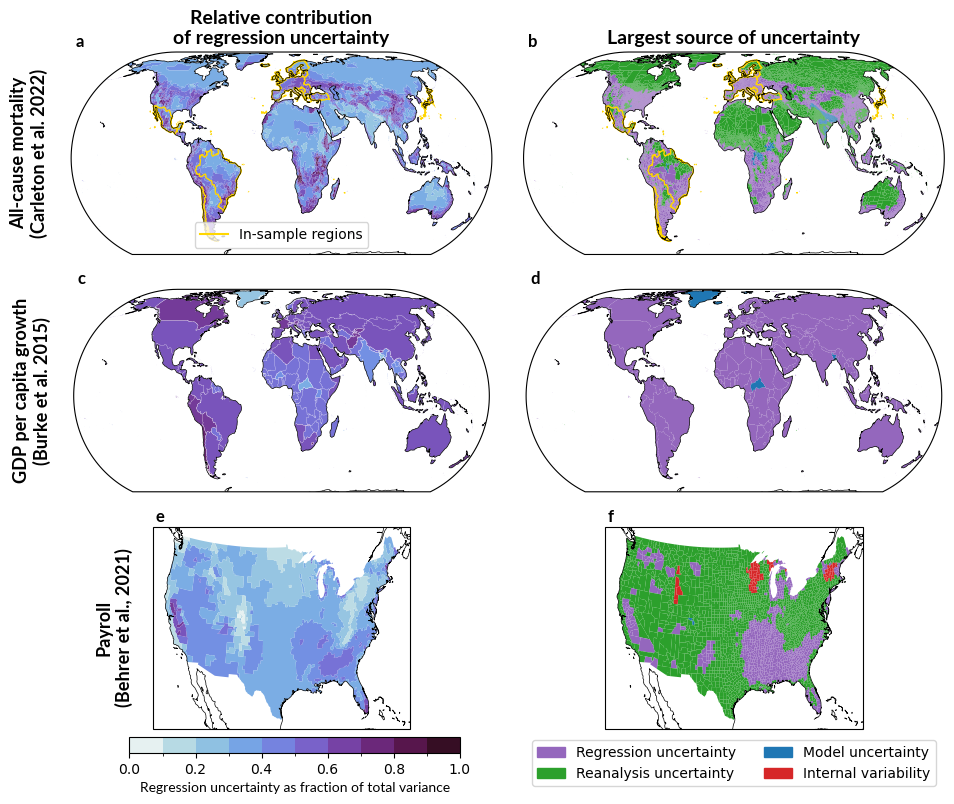

In [13]:

save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/regunc_maps'

gwl = 2

fig = plt.figure(figsize=(10,8))

cat_colors = {'uncreg':'tab:purple',
              'uncobs':'tab:green',
              'uncmod':'tab:blue',
              'uncint':'tab:red'}
names = {'uncreg':'Regression uncertainty',
         'uncobs':'Reanalysis uncertainty',
         'uncmod':'Model uncertainty',
         'uncint':'Internal variability'}
proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                   'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                   'payroll':'Payroll\n(Behrer et al., 2021)'}

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}


cbar_params = {'vmin':0,'vmax':1,'cmap':cmocean.cm.dense,'levels':11}
clabel = 'Regression uncertainty as fraction of total variance' 

mort_insamp_border = True
if mort_insamp_border:
    mort_insamp = gpd.read_file(dir_list['aux']+'geo_data/mortality_insamp_world_plugged.shp')
    mort_insamp = mort_insamp.simplify(tolerance=0.25)

for row_idx,proc in enumerate(params_proc):
    # Load shapefile
    gdf = load_shp(proc)

    # Load partitioned uncertainty 
    fn_uncerts = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}_wregunc.zarr'
    uncerts_all = xr.open_zarr(fn_uncerts).isel(sample=0)
    uncerts_all = uncerts_all.set_index({'poly_idx':'locid'})

    plot_data = uncerts_all.sel(gwl=gwl,typ='norm',poly_idx=gdf.locid.values).load()
    
    for col_idx in np.arange(0,2):
        ax = plt.subplot(len(params_proc),2,row_idx*2+col_idx+1,projection=projs[proc])
        # Subplot label
        ax.annotate(string.ascii_lowercase[row_idx*2+col_idx],(0.01,1.01),xycoords = 'axes fraction',
                            fontweight='bold',fontsize=12,va='bottom',font=extra_fonts['lato-bold'])

        ax.coastlines(linewidth=0.5)
        
        
        if col_idx == 0:

            if 'levels' in cbar_params:
                gdf_tmp = gdf.copy()
                gdf_tmp['colors'] = create_segcmap(uncerts_all.sel(gwl=2,typ='norm',poly_idx = gdf.locid.values).uncreg,
                                                cbar_params)
                gdf_tmp = gdf_tmp.dissolve(by='colors').reset_index()
                
                gdf_tmp.plot(color=gdf_tmp.colors,edgecolor='none',transform=ccrs.PlateCarree(),ax=ax)
                # Plot national boundaries at least
                if proc == 'gdppc':
                    gdf.plot(ax=ax,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())
                    
            else:
                fig,ax=plot_map(uncerts_all.sel(gwl=2,typ='norm',poly_idx = gdf.locid.values).uncreg,
                             gdf,**cbar_params,fig=fig,ax=ax)
            if row_idx == 0:
                ax.set_title('Relative contribution\nof regression uncertainty',font=extra_fonts['lato-bold'],fontsize=14)
            else:
                ax.set_title('')

            if row_idx == len(params_proc)-1:
                cax = fig.add_axes([ax.get_position().x0-0.05,
                    ax.get_position().y0-0.05,
                    ax.get_position().width+0.1,
                    0.02])
                if 'levels' in cbar_params:
                    levels = mpl.ticker.MaxNLocator(nbins=cbar_params['levels']).tick_values(cbar_params['vmin'],cbar_params['vmax'])
                    norm = mpl.colors.BoundaryNorm(levels, ncolors=cbar_params['cmap'].N, clip=True)
                else:
                    norm = mpl.colors.Normalize(vmin=cbar_params['vmin'],vmax=cbar_params['vmax'])
                sm = plt.cm.ScalarMappable(cmap=cbar_params['cmap'],norm=norm)
                cbar = plt.colorbar(sm,cax=cax,label=clabel,orientation='horizontal')
                cbar.set_label(clabel,font=extra_fonts['lato'])

            # Row labels
            if proc == 'payroll':
                row_ann_pos = (-0.15,0.5)
            else:
                row_ann_pos = (-0.1,0.5)
            ax.annotate(proc_full_names[proc],
                            row_ann_pos,xycoords = 'axes fraction',
                            fontweight='bold',fontsize=13,va='center',ha='center',
                            rotation=90,font=extra_fonts['lato-bold'])

        elif col_idx == 1:
            # Get which uncertainty source is most important 
            srcs = plot_data.to_dataarray()
            src_idxs = nan_argmax_xr(srcs,dim='variable').dropna('poly_idx').astype(int)
            srcs = srcs.sel(poly_idx = src_idxs.poly_idx).isel(variable=src_idxs)['variable']
            srcs = srcs.to_dataframe()['variable'].iloc[:,[0]]

            # Set colors for each dominant source of uncertainty
            srcs['colors'] = 'grey'
            for cat in cat_colors:
                srcs['colors'] = srcs['colors'].where(srcs['variable']!=cat,cat_colors[cat])
        
            srcs = srcs.reset_index().rename({'poly_idx':'locid'},axis=1)

            # Merge into gdf
            gdf = gdf.set_index('locid').join(srcs.set_index('locid'))
            gdf = gdf.iloc[(~gdf['colors'].isnull()).values,:]

            gdf.plot(color=gdf['colors'],transform=ccrs.PlateCarree(),ax=ax)


            if row_idx == 0:
                ax.set_title('Largest source of uncertainty',font=extra_fonts['lato-bold'],fontsize=14)
            else:
                ax.set_title('')

            # Legend
            if row_idx == len(params_proc)-1:
                handles = [
                    mpatches.Patch(color=color, label=names[label])
                    for label, color in cat_colors.items()
                ]
                ax.legend(handles=handles,
                          bbox_to_anchor = (0.5,-0.02),
                          loc = 'upper center',
                          ncol = 2)
        # In-sample border for mortality
        if mort_insamp_border and (proc == 'mortality'):
            mort_insamp.plot(edgecolor='gold',facecolor='none',ax=ax,transform=ccrs.PlateCarree())
            if col_idx == 0:
                ax.legend(handles = [mpl.lines.Line2D([0,0],[0,0],color='gold',label='In-sample regions')],
                              loc = 'lower center')


plt.tight_layout()

if save_fig:
    utility_print(output_fn)